# Phishing URL Detector - Exploratory Data Analysis

This notebook explores the **engineered URL features** used to train the
classifier. Every row comes from the PhiUSIIL dataset (235,795 labelled URLs),
after cleaning and feature extraction by `src.preprocessing`.

Label convention: **1 = phishing**, **0 = legitimate**.

The goal is to understand class balance, URL structure and which features
separate the two classes before training models.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Work from the project root regardless of where the notebook is executed.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "config").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config.settings import EDA_DIR, PROCESSED_DATASET_PATH
from src.feature_extraction import FEATURE_NAMES

EDA_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.max_columns", 60)

print("Processed dataset:", PROCESSED_DATASET_PATH)
print("Figures folder:  ", EDA_DIR)

Processed dataset: D:\Projects\phishing URL Detector\data\processed\url_features.csv
Figures folder:   D:\Projects\phishing URL Detector\results\eda


## 1. Load the engineered dataset

In [2]:
df = pd.read_csv(PROCESSED_DATASET_PATH)
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]} ({len(FEATURE_NAMES)} engineered features + url + label)")
df.head(5)

Rows: 235,362
Columns: 40 (38 engineered features + url + label)


,url,label,url_length,hostname_length,path_length,query_length,num_dots,num_hyphens,num_underscores,num_slashes,num_question_marks,num_equal_signs,num_at_symbols,num_ampersands,num_special_chars,num_digits,digit_ratio,num_letters,letter_ratio,num_subdomains,num_params,path_depth,tld_length,has_https,has_ip_address,has_suspicious_keyword,num_suspicious_keywords,has_url_shortener,has_brand_term,hostname_is_long,has_unusual_port,has_port,has_punycode,suspicious_tld,num_percent_encoded,has_hex_encoding,has_double_slash_in_path,has_obfuscation,is_long_url,hostname_hyphen_count
0,https://www.southbankmosaics.com,0,32,24,0,0,2,0,0,2,0,0,0,0,1,0,0.0,27,0.8438,1,0,0,3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,https://www.uni-mainz.de,0,24,16,0,0,2,1,0,2,0,0,0,0,1,0,0.0,18,0.7500,1,0,0,2,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,https://www.voicefmradio.co.uk,0,30,22,0,0,3,0,0,2,0,0,0,0,1,0,0.0,24,0.8000,2,0,0,2,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,https://www.sfnmjournal.com,0,27,19,0,0,2,0,0,2,0,0,0,0,1,0,0.0,22,0.8148,1,0,0,3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,https://www.rewildingargentina.org,0,34,26,0,0,2,0,0,2,0,0,0,0,1,0,0.0,29,0.8529,1,0,0,3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 2. Data quality: missing values and duplicates

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique_values": df.nunique(),
})
print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate URLs:", int(df["url"].duplicated().sum()))
print("Duplicate feature rows:", int(df[list(FEATURE_NAMES)].duplicated().sum()))
quality.head(12)

Total missing values: 0
Duplicate URLs: 0


Duplicate feature rows: 203349


,dtype,missing,unique_values
url,str,0,235362
label,int64,0,2
url_length,int64,0,473
hostname_length,int64,0,101
path_length,int64,0,210
query_length,int64,0,393
num_dots,int64,0,22
num_hyphens,int64,0,32
num_underscores,int64,0,28
num_slashes,int64,0,28


The raw dataset contained 235,795 rows. Cleaning removed **425 duplicate URLs**
and **8 malformed URLs**, leaving **235,362** usable rows. No missing values
remain in the feature matrix.

## 3. Class distribution

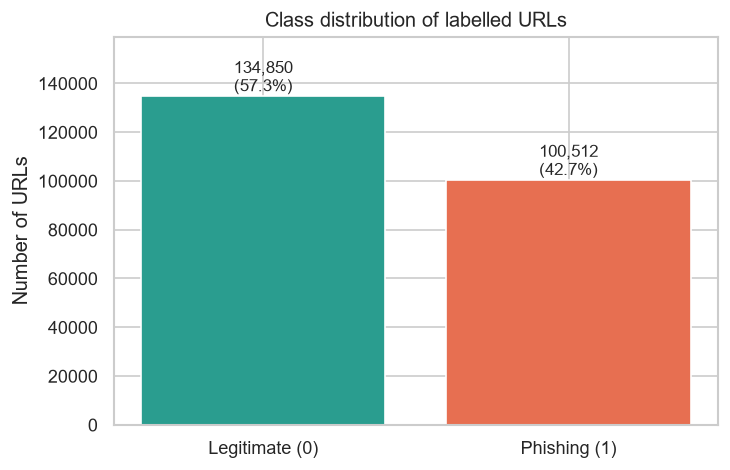

Legitimate: 134,850 (57.29%)
Phishing:   100,512 (42.71%)
Imbalance ratio: 1.34 : 1


In [4]:
counts = df["label"].value_counts().sort_index()
labels = ["Legitimate (0)", "Phishing (1)"]
colors = ["#2A9D8F", "#E76F51"]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(labels, [counts.get(0, 0), counts.get(1, 0)], color=colors)
for bar, value in zip(bars, [counts.get(0, 0), counts.get(1, 0)]):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:,}\n({value / len(df):.1%})",
            ha="center", va="bottom", fontsize=10)
ax.set_title("Class distribution of labelled URLs")
ax.set_ylabel("Number of URLs")
ax.set_ylim(0, max(counts) * 1.18)
fig.savefig(EDA_DIR / "class_distribution.png")
plt.show()

print(f"Legitimate: {counts.get(0, 0):,} ({counts.get(0, 0) / len(df):.2%})")
print(f"Phishing:   {counts.get(1, 0):,} ({counts.get(1, 0) / len(df):.2%})")
print(f"Imbalance ratio: {counts.max() / counts.min():.2f} : 1")

The dataset is mildly imbalanced (about 57% legitimate / 43% phishing). This is
not extreme, but all models still use `class_weight="balanced"` so the minority
class is not under-weighted.

## 4. URL length and hostname length

In [5]:
length_stats = df.groupby("label")[["url_length", "hostname_length", "path_length"]].agg(
    ["mean", "median", "max"]
).round(1)
length_stats.index = ["Legitimate", "Phishing"]
length_stats

url_length              hostname_length             path_length  \
                 mean median   max            mean median  max        mean   
Legitimate       27.2   27.0    58            19.2   19.0   50         0.0   
Phishing         45.9   34.0  1769            24.4   22.0  110         8.5   

                        
           median  max  
Legitimate    0.0    0  
Phishing      1.0  894

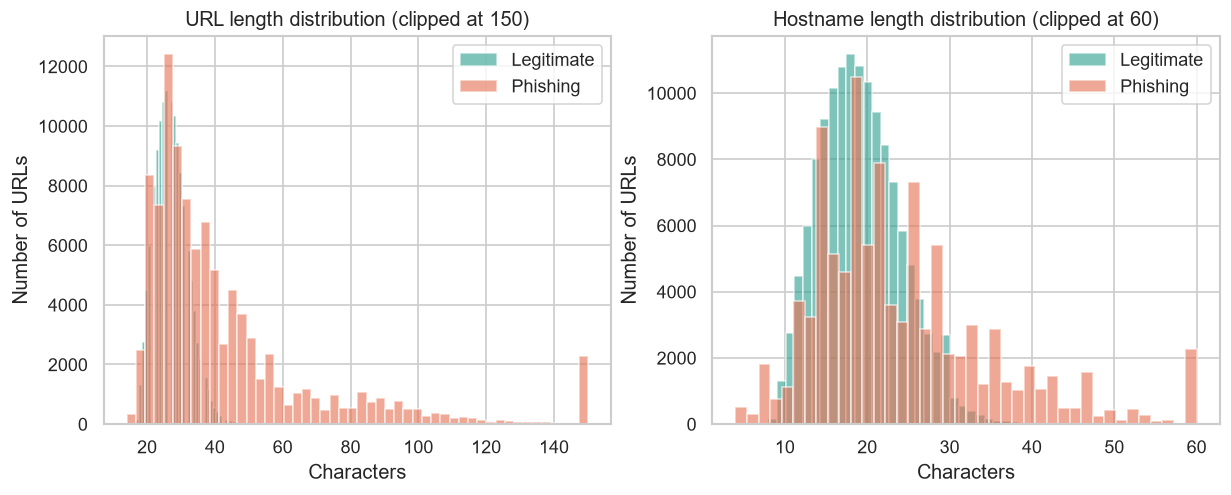

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

for label, name, color in [(0, "Legitimate", "#2A9D8F"), (1, "Phishing", "#E76F51")]:
    subset = df[df["label"] == label]
    axes[0].hist(subset["url_length"].clip(upper=150), bins=50, alpha=0.6, label=name, color=color)
    axes[1].hist(subset["hostname_length"].clip(upper=60), bins=40, alpha=0.6, label=name, color=color)

axes[0].set_title("URL length distribution (clipped at 150)")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Number of URLs")
axes[1].set_title("Hostname length distribution (clipped at 60)")
axes[1].set_xlabel("Characters")
axes[1].set_ylabel("Number of URLs")
for ax in axes:
    ax.legend()
fig.savefig(EDA_DIR / "length_distributions.png")
plt.show()

Phishing URLs are longer on average and have longer hostnames, which matches
the intuition that attackers add words, subdomains and parameters to appear
convincing.

## 5. Special-character analysis

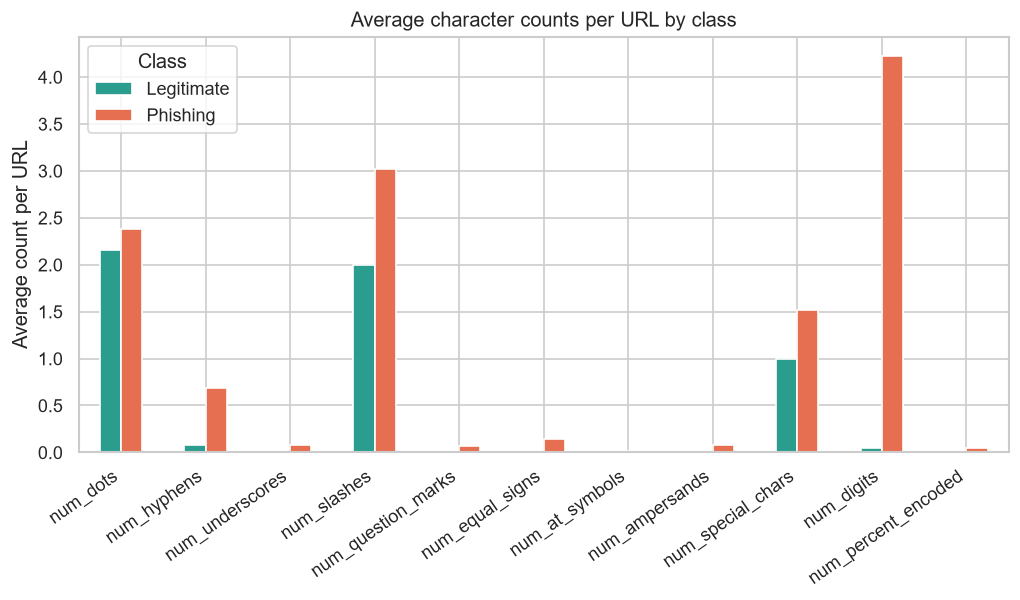

,Legitimate,Phishing
num_dots,2.16,2.38
num_hyphens,0.08,0.69
num_underscores,0.00,0.08
num_slashes,2.00,3.02
num_question_marks,0.00,0.07
num_equal_signs,0.00,0.14
num_at_symbols,0.00,0.02
num_ampersands,0.00,0.08
num_special_chars,1.00,1.52
num_digits,0.05,4.22


In [7]:
count_features = [
    "num_dots", "num_hyphens", "num_underscores", "num_slashes",
    "num_question_marks", "num_equal_signs", "num_at_symbols",
    "num_ampersands", "num_special_chars", "num_digits", "num_percent_encoded",
]
means = df.groupby("label")[count_features].mean().T.round(2)
means.columns = ["Legitimate", "Phishing"]

fig, ax = plt.subplots(figsize=(10, 4.5))
means.plot(kind="bar", ax=ax, color=["#2A9D8F", "#E76F51"])
ax.set_title("Average character counts per URL by class")
ax.set_ylabel("Average count per URL")
ax.set_xlabel("")
plt.xticks(rotation=35, ha="right")
ax.legend(title="Class")
fig.savefig(EDA_DIR / "special_character_analysis.png")
plt.show()
means

## 6. Feature comparison between classes

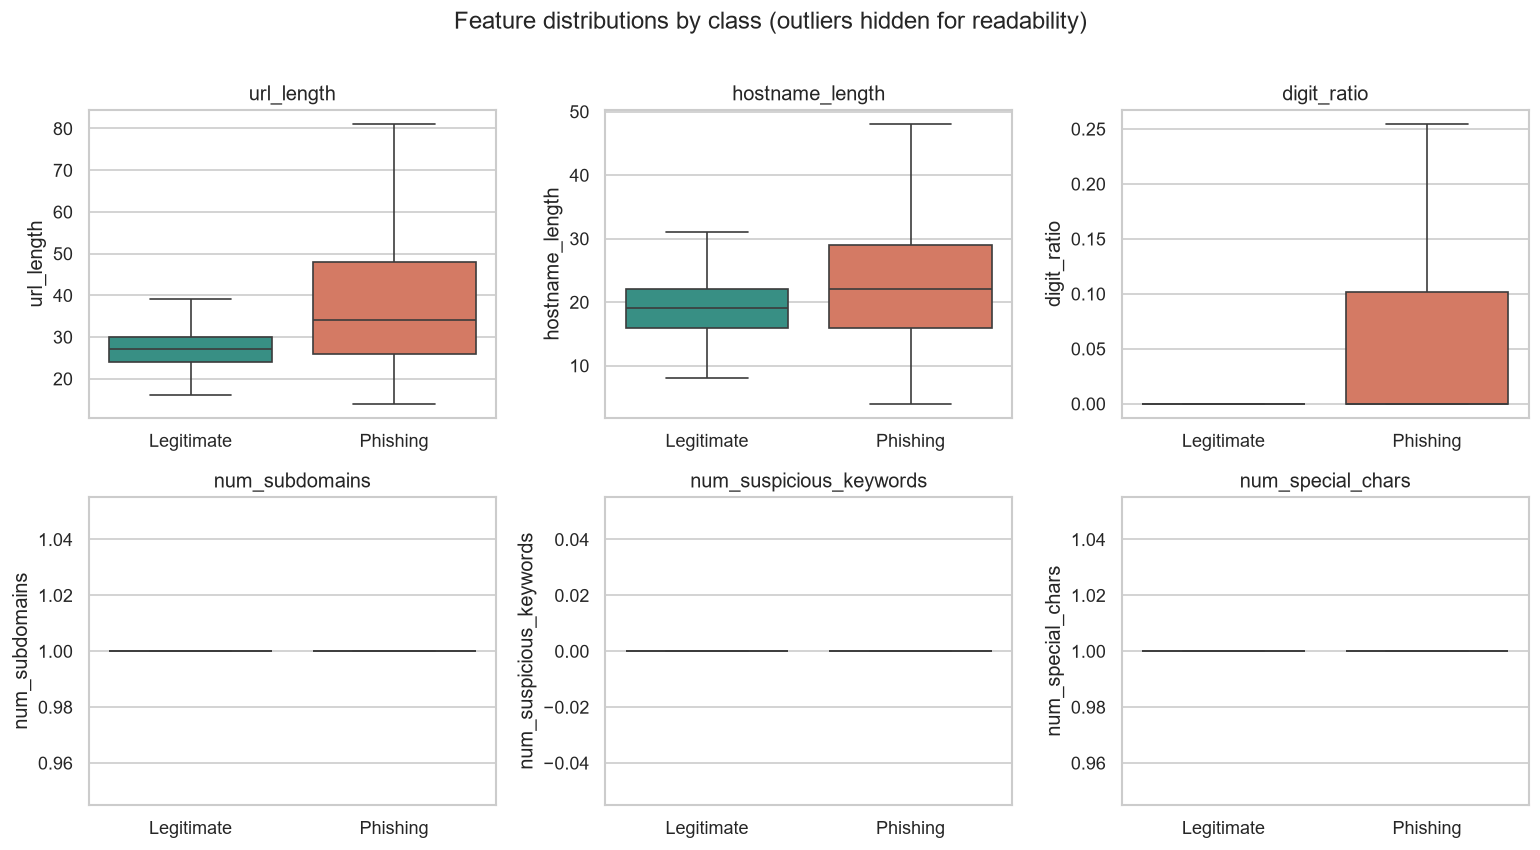

In [8]:
box_features = [
    "url_length", "hostname_length", "digit_ratio",
    "num_subdomains", "num_suspicious_keywords", "num_special_chars",
]
plot_df = df[box_features + ["label"]].copy()
plot_df["Class"] = plot_df["label"].map({0: "Legitimate", 1: "Phishing"})

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, feature in zip(axes.ravel(), box_features):
    sns.boxplot(
        data=plot_df, x="Class", y=feature, ax=ax,
        hue="Class", palette={"Legitimate": "#2A9D8F", "Phishing": "#E76F51"},
        showfliers=False, legend=False,
    )
    ax.set_title(feature)
    ax.set_xlabel("")
fig.suptitle("Feature distributions by class (outliers hidden for readability)", y=1.01)
fig.tight_layout()
fig.savefig(EDA_DIR / "feature_comparison.png")
plt.show()

## 7. Correlation analysis

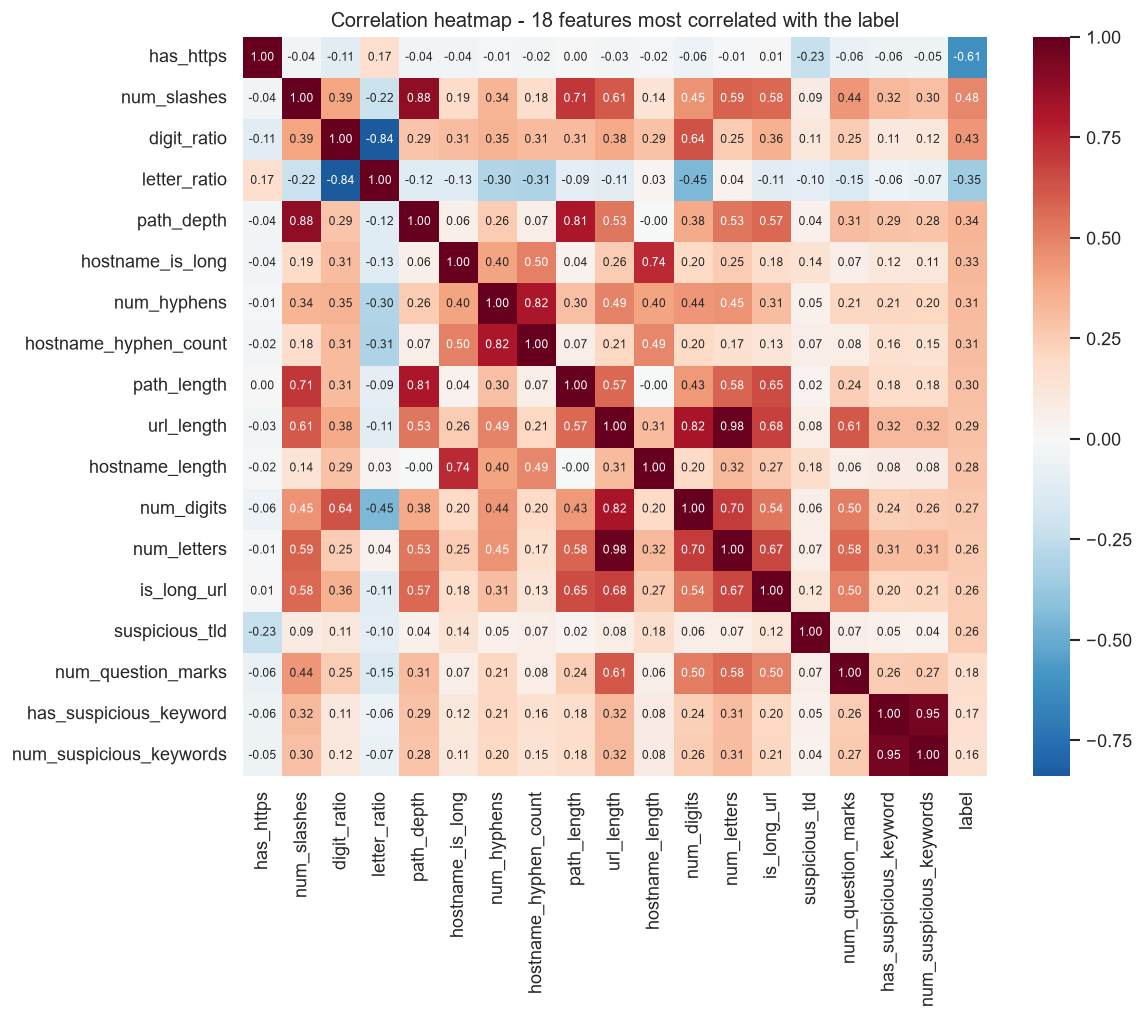

,correlation_with_phishing
has_https,-0.614
num_slashes,0.484
digit_ratio,0.433
letter_ratio,-0.351
path_depth,0.335
hostname_is_long,0.326
num_hyphens,0.311
hostname_hyphen_count,0.305
path_length,0.300
url_length,0.292


In [9]:
corr = df[list(FEATURE_NAMES) + ["label"]].corr(numeric_only=True)
label_corr = corr["label"].drop("label").sort_values(key=np.abs, ascending=False)

top_features = label_corr.head(18).index.tolist()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr.loc[top_features, top_features + ["label"]],
    annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7}, ax=ax,
)
ax.set_title("Correlation heatmap - 18 features most correlated with the label")
fig.savefig(EDA_DIR / "correlation_heatmap.png")
plt.show()

label_corr.head(12).round(3).to_frame("correlation_with_phishing")

## 8. HTTPS usage and suspicious TLDs

Share of each class using HTTPS:


,No HTTPS,HTTPS
Legitimate,0.000,1.000
Phishing,0.514,0.486


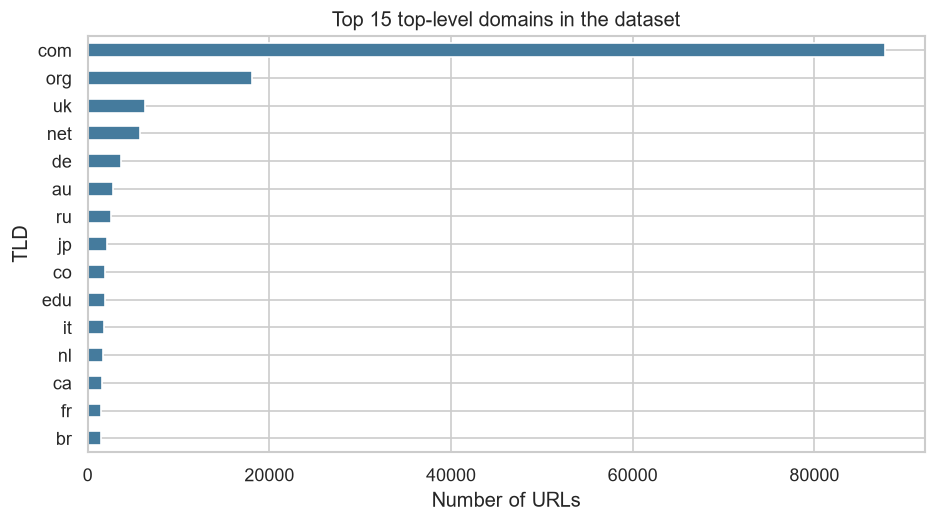

In [10]:
https_table = pd.crosstab(df["label"], df["has_https"], normalize="index").round(3)
https_table.index = ["Legitimate", "Phishing"]
https_table.columns = ["No HTTPS", "HTTPS"]
print("Share of each class using HTTPS:")
display(https_table)

tlds_extracted = df["url"].str.extract(r"://[^/]+?\.([a-z]{2,})$", expand=False)
top_tld = tlds_extracted.value_counts().head(15)

fig, ax = plt.subplots(figsize=(9, 4.5))
top_tld.iloc[::-1].plot(kind="barh", ax=ax, color="#457B9D")
ax.set_title("Top 15 top-level domains in the dataset")
ax.set_xlabel("Number of URLs")
ax.set_ylabel("TLD")
fig.savefig(EDA_DIR / "top_tlds.png")
plt.show()

Legitimate URLs in this dataset almost always use HTTPS, while a large share of
phishing URLs do not. This is a genuinely useful signal, but it also reflects
how the dataset was collected: HTTPS alone must never be treated as proof that
a site is safe.

**Important dataset bias:** 100% of the legitimate URLs in this dataset use
HTTPS, while only ~49% of phishing URLs do. A model can therefore learn a
shortcut ("HTTP means phishing"). The evaluation numbers should be read with
this bias in mind, and the tool is not a substitute for real security analysis.

In [11]:
print("Mean values by class:")
df.groupby("label")[["has_https", "has_ip_address", "suspicious_tld",
                     "has_suspicious_keyword", "has_brand_term",
                     "has_url_shortener", "has_unusual_port"]].mean().round(3)

Mean values by class:


,has_https,has_ip_address,suspicious_tld,has_suspicious_keyword,has_brand_term,has_url_shortener,has_unusual_port
label,,,,,,,
0,1.000,0.000,0.001,0.000,0.00,0.000,0.0
1,0.486,0.006,0.114,0.049,0.02,0.008,0.0


## 9. Key takeaways

1. **Class balance:** 57% legitimate / 43% phishing; balanced class weights are still applied.
2. **Length matters:** phishing URLs and hostnames are longer on average.
3. **Digits and special characters** are more frequent in phishing URLs.
4. **HTTPS** is strongly associated with the legitimate class in this dataset.
5. **Keywords and suspicious TLDs** are important but rare, so they should be combined with other signals.
6. **Correlated features:** several length/count features are correlated, which is fine for tree models but motivates scaling for Logistic Regression.

These observations guided the feature set and the decision to compare a linear
model, a single tree and an ensemble.

## 10. Limitations of this EDA

- The dataset is a snapshot of one collection effort; real-world URL
  distributions change over time.
- Legitimate URLs are mostly homepages, while many phishing URLs include paths
  and parameters. Models can therefore over-weight "has a path"-style signals.
- Features are purely lexical. Page content, certificates, hosting reputation
  and domain age are intentionally **not** used.
- Correlation does not imply causation; these plots describe this dataset only.